# Exploratory Data Analysis — Class Balance

This notebook studies the **number of images** in the dataset and how they relate to their **labels**.

**Label format (YOLO):** each image `X.jpg` in `images/` has a matching `X.txt` in `labels/`.
Each line of a label file is `class x_center y_center width height` (normalised coordinates).

| Class id | Meaning |
|---|---|
| `0` | smoke |
| `1` | fire |

An image with **no label file**, or with an **empty label file**, has no fire or smoke. We call these *background* images.

**Plan**
1. Load every split and build one table with one row per image and one row per bounding box.
2. Check data integrity (missing or orphan labels, malformed lines).
3. **Full dataset:** image counts, *fire/smoke vs background* balance, then the balance of each class.
4. **Each split** (train / val / test): the same analysis, followed by a comparison between splits.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option("display.float_format", "{:.2f}".format)

## 1. Configuration

In [2]:
# Locate the project root (the folder that contains `data/`), wherever the notebook is run from
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
DATA_ROOT = PROJECT_ROOT / "data" / "original_dataset"

SPLITS = ["train", "val", "test"]
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
CLASS_NAMES = {0: "smoke", 1: "fire"}

# Image-level categories (an image can contain both classes)
CATEGORIES = ["background", "smoke_only", "fire_only", "fire_and_smoke"]

# Colours: fixed per entity, used the same way in every chart
COLORS = {
    "smoke": "#2a78d6",
    "fire": "#eb6834",
    "fire_and_smoke": "#1baf7a",
    "smoke_only": "#2a78d6",
    "fire_only": "#eb6834",
    "background": "#9a9a94",
    "fire/smoke": "#eb6834",
}
TEXT, MUTED, GRID = "#1f1f1e", "#6b6b66", "#e4e4e0"

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": GRID,
    "axes.labelcolor": MUTED,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlecolor": TEXT,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "legend.frameon": False,
})

print("Data root:", DATA_ROOT)

Data root: /home/campo/containers/fire-detection/data/original_dataset


## 2. Load the dataset

Two tables are built:
- `images_df`: one row per image, with whether it has a label file, its number of boxes per class, and its image-level category.
- `boxes_df`: one row per bounding box.

In [3]:
def parse_label_file(path):
    """Return (boxes, malformed_lines) for a YOLO label file."""
    boxes, malformed = [], []
    for line_no, line in enumerate(path.read_text().splitlines(), start=1):
        if not line.strip():
            continue
        parts = line.split()
        try:
            cls = int(float(parts[0]))
            coords = [float(v) for v in parts[1:5]]
        except (ValueError, IndexError):
            malformed.append((path.name, line_no, line))
            continue
        if len(parts) != 5 or cls not in CLASS_NAMES:
            malformed.append((path.name, line_no, line))
            continue
        boxes.append((cls, *coords))
    return boxes, malformed


def image_category(n_smoke, n_fire):
    if n_smoke and n_fire:
        return "fire_and_smoke"
    if n_fire:
        return "fire_only"
    if n_smoke:
        return "smoke_only"
    return "background"


image_rows, box_rows, malformed_rows, orphan_rows = [], [], [], []

for split in SPLITS:
    img_dir, lbl_dir = DATA_ROOT / split / "images", DATA_ROOT / split / "labels"
    images = sorted(p for p in img_dir.glob("*") if p.suffix.lower() in IMAGE_EXTS) if img_dir.is_dir() else []
    labels = {p.stem: p for p in lbl_dir.glob("*.txt")} if lbl_dir.is_dir() else {}

    image_stems = {p.stem for p in images}
    orphan_rows += [(split, name) for name in sorted(set(labels) - image_stems)]

    for img in images:
        lbl = labels.get(img.stem)
        boxes, malformed = parse_label_file(lbl) if lbl else ([], [])
        malformed_rows += [(split, *m) for m in malformed]

        n_smoke = sum(b[0] == 0 for b in boxes)
        n_fire = sum(b[0] == 1 for b in boxes)
        image_rows.append({
            "split": split,
            "image": img.name,
            "has_label_file": lbl is not None,
            "empty_label_file": lbl is not None and not boxes,
            "n_boxes": len(boxes),
            "n_smoke": n_smoke,
            "n_fire": n_fire,
            "category": image_category(n_smoke, n_fire),
        })
        box_rows += [
            {"split": split, "image": img.name, "class_id": c, "class": CLASS_NAMES[c],
             "x_center": x, "y_center": y, "width": w, "height": h}
            for c, x, y, w, h in boxes
        ]

images_df = pd.DataFrame(image_rows)
boxes_df = pd.DataFrame(box_rows, columns=["split", "image", "class_id", "class",
                                           "x_center", "y_center", "width", "height"])

images_df["split"] = pd.Categorical(images_df["split"], categories=SPLITS, ordered=True)
images_df["category"] = pd.Categorical(images_df["category"], categories=CATEGORIES, ordered=True)
images_df["has_fire_or_smoke"] = images_df["n_boxes"] > 0
boxes_df["split"] = pd.Categorical(boxes_df["split"], categories=SPLITS, ordered=True)

print(f"Images loaded: {len(images_df):,}  |  Bounding boxes loaded: {len(boxes_df):,}")
images_df.head()

Images loaded: 21,527  |  Bounding boxes loaded: 26,557


,split,image,has_label_file,empty_label_file,n_boxes,n_smoke,n_fire,category,has_fire_or_smoke
0,train,AoF00000.jpg,True,True,0,0,0,background,False
1,train,AoF00001.jpg,True,False,1,0,1,fire_only,True
2,train,AoF00002.jpg,True,False,1,1,0,smoke_only,True
3,train,AoF00003.jpg,True,True,0,0,0,background,False
4,train,AoF00004.jpg,True,True,0,0,0,background,False


## 3. Data integrity

Before looking at balance, check that images and labels match:
- **images without a label file** → background (allowed by the dataset convention)
- **empty label files** → background
- **orphan labels** (a label file whose image is missing) → should be 0
- **malformed lines** (wrong number of fields, unknown class id) → should be 0

In [4]:
integrity = (
    images_df.groupby("split", observed=False)
    .agg(images=("image", "size"),
         label_files=("has_label_file", "sum"),
         images_without_label_file=("has_label_file", lambda s: (~s).sum()),
         empty_label_files=("empty_label_file", "sum"))
)
integrity["orphan_label_files"] = pd.Series([s for s, _ in orphan_rows], dtype="object").value_counts() \
    .reindex(SPLITS, fill_value=0)
integrity["malformed_lines"] = pd.Series([m[0] for m in malformed_rows], dtype="object").value_counts() \
    .reindex(SPLITS, fill_value=0)
integrity.loc["total"] = integrity.sum()
display(integrity.astype(int))

empty_splits = [s for s in SPLITS if integrity.loc[s, "images"] == 0]
if empty_splits:
    print(f"WARNING: these splits contain no images and are skipped in the per-split analysis: {empty_splits}")
if malformed_rows:
    display(pd.DataFrame(malformed_rows, columns=["split", "file", "line", "content"]).head(20))

,images,label_files,images_without_label_file,empty_label_files,orphan_label_files,malformed_lines
split,,,,,,
train,14122,14122,0,6458,0,0
val,3099,3099,0,1375,0,0
test,4306,4306,0,2005,0,0
total,21527,21527,0,9838,0,0


## 4. Helper functions

The same tables and charts are used for the full dataset and for each split, so they are written once here.

In [5]:
def pct_table(counts):
    """Turn a count Series into a table with counts and percentages."""
    total = counts.sum()
    return pd.DataFrame({"count": counts.astype(int),
                         "percent": counts / total * 100 if total else 0.0})


def binary_balance(df):
    counts = df["has_fire_or_smoke"].map({True: "fire/smoke", False: "background"}) \
        .value_counts().reindex(["fire/smoke", "background"], fill_value=0)
    table = pct_table(counts)
    pos, neg = counts["fire/smoke"], counts["background"]
    ratio = (max(pos, neg) / min(pos, neg)) if min(pos, neg) else np.inf
    return table, ratio


def category_balance(df):
    return pct_table(df["category"].value_counts().reindex(CATEGORIES, fill_value=0))


def class_presence(df):
    """Images that contain at least one box of each class (one image can count for both)."""
    n = len(df)
    counts = pd.Series({"smoke": (df["n_smoke"] > 0).sum(), "fire": (df["n_fire"] > 0).sum()})
    return pd.DataFrame({"images": counts.astype(int),
                         "percent_of_all_images": counts / n * 100 if n else 0.0})


def instance_balance(bdf):
    return pct_table(bdf["class"].value_counts().reindex(["smoke", "fire"], fill_value=0))


def boxes_per_image(df):
    """Box count statistics, only over images that contain at least one box."""
    pos = df[df["n_boxes"] > 0]
    return pos[["n_boxes", "n_smoke", "n_fire"]].describe().T


def label_bars(ax, bars, values, total):
    for bar, v in zip(bars, values):
        ax.annotate(f"{v:,}\n({v / total:.1%})" if total else "0",
                    (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                    xytext=(0, 3), textcoords="offset points",
                    ha="center", va="bottom", fontsize=9, color=TEXT)


def bar_chart(ax, counts, title, ylabel="images", total=None):
    """`total` is the denominator for the % labels (defaults to the sum of the bars)."""
    names = list(counts.index)
    bars = ax.bar(names, counts.values, width=0.6,
                  color=[COLORS.get(n, MUTED) for n in names],
                  edgecolor="white", linewidth=2)
    label_bars(ax, bars, counts.values, counts.sum() if total is None else total)
    ax.set_title(title, loc="left")
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, max(counts.max(), 1) * 1.22)
    ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
    ax.tick_params(axis="x", length=0)


def plot_overview(df, bdf, scope):
    """Four panels: binary balance, image categories, class presence, box instances."""
    fig, axes = plt.subplots(1, 4, figsize=(18, 4.4))
    bar_chart(axes[0], binary_balance(df)[0]["count"], "Fire/smoke vs background")
    bar_chart(axes[1], category_balance(df)["count"], "Image categories")
    axes[1].tick_params(axis="x", labelrotation=15)
    bar_chart(axes[2], class_presence(df)["images"], "Images containing each class\n(% of all images)",
              total=len(df))
    bar_chart(axes[3], instance_balance(bdf)["count"], "Bounding boxes per class", ylabel="boxes")
    fig.suptitle(f"Class balance — {scope}  ({len(df):,} images, {len(bdf):,} boxes)",
                 x=0.01, ha="left", fontsize=14, fontweight="bold", color=TEXT)
    fig.tight_layout()
    plt.show()


def report(df, bdf, scope):
    """Print every statistics table for one scope (full dataset or one split), then plot."""
    print(f"=== {scope} ===")
    print(f"Total images: {len(df):,}   |   Total bounding boxes: {len(bdf):,}\n")

    table, ratio = binary_balance(df)
    print("Fire/smoke vs background (image level)")
    display(table)
    print(f"Imbalance ratio (majority / minority): {ratio:.2f} : 1\n")

    print("Image categories")
    display(category_balance(df))

    print("Images containing each class (an image with both classes counts in both rows)")
    display(class_presence(df))

    print("Bounding boxes per class (instance level)")
    display(instance_balance(bdf))

    print("Boxes per image (only images with at least one box)")
    display(boxes_per_image(df))

    plot_overview(df, bdf, scope)

## 5. Full dataset

### 5.1 Number of images per split

,count,percent
split,,
train,14122.00,65.60
val,3099.00,14.40
test,4306.00,20.00
total,21527.00,100.00


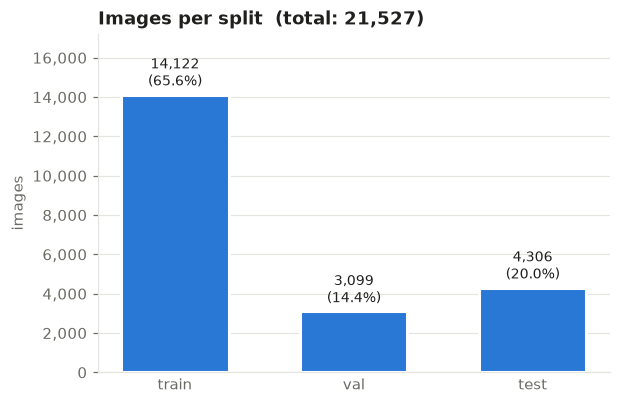

In [6]:
split_counts = images_df["split"].value_counts().reindex(SPLITS, fill_value=0)
split_table = pct_table(split_counts)
split_table.loc["total"] = [split_counts.sum(), 100.0]
display(split_table)

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(SPLITS, split_counts.values, width=0.6, color="#2a78d6", edgecolor="white", linewidth=2)
label_bars(ax, bars, split_counts.values, split_counts.sum())
ax.set_title(f"Images per split  (total: {split_counts.sum():,})", loc="left")
ax.set_ylabel("images")
ax.set_ylim(0, max(split_counts.max(), 1) * 1.22)
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax.tick_params(axis="x", length=0)
plt.show()

### 5.2 Class balance (all splits together)

Read the results at three levels:
- **Fire/smoke vs background:** does the image contain anything?
- **Image categories:** smoke only, fire only, both, or nothing.
- **Instances:** how many smoke and fire boxes there are. This is what the detection loss sees.

=== full dataset ===
Total images: 21,527   |   Total bounding boxes: 26,557

Fire/smoke vs background (image level)


,count,percent
has_fire_or_smoke,,
fire/smoke,11689,54.30
background,9838,45.70


Imbalance ratio (majority / minority): 1.19 : 1

Image categories


,count,percent
category,,
background,9838,45.70
smoke_only,5867,27.25
fire_only,1164,5.41
fire_and_smoke,4658,21.64


Images containing each class (an image with both classes counts in both rows)


,images,percent_of_all_images
smoke,10525,48.89
fire,5822,27.05


Bounding boxes per class (instance level)


,count,percent
class,,
smoke,11865,44.68
fire,14692,55.32


Boxes per image (only images with at least one box)


,count,mean,std,min,25%,50%,75%,max
n_boxes,11689.00,2.27,1.96,1.00,1.00,1.00,3.00,23.00
n_smoke,11689.00,1.02,0.54,0.00,1.00,1.00,1.00,10.00
n_fire,11689.00,1.26,1.89,0.00,0.00,0.00,2.00,22.00


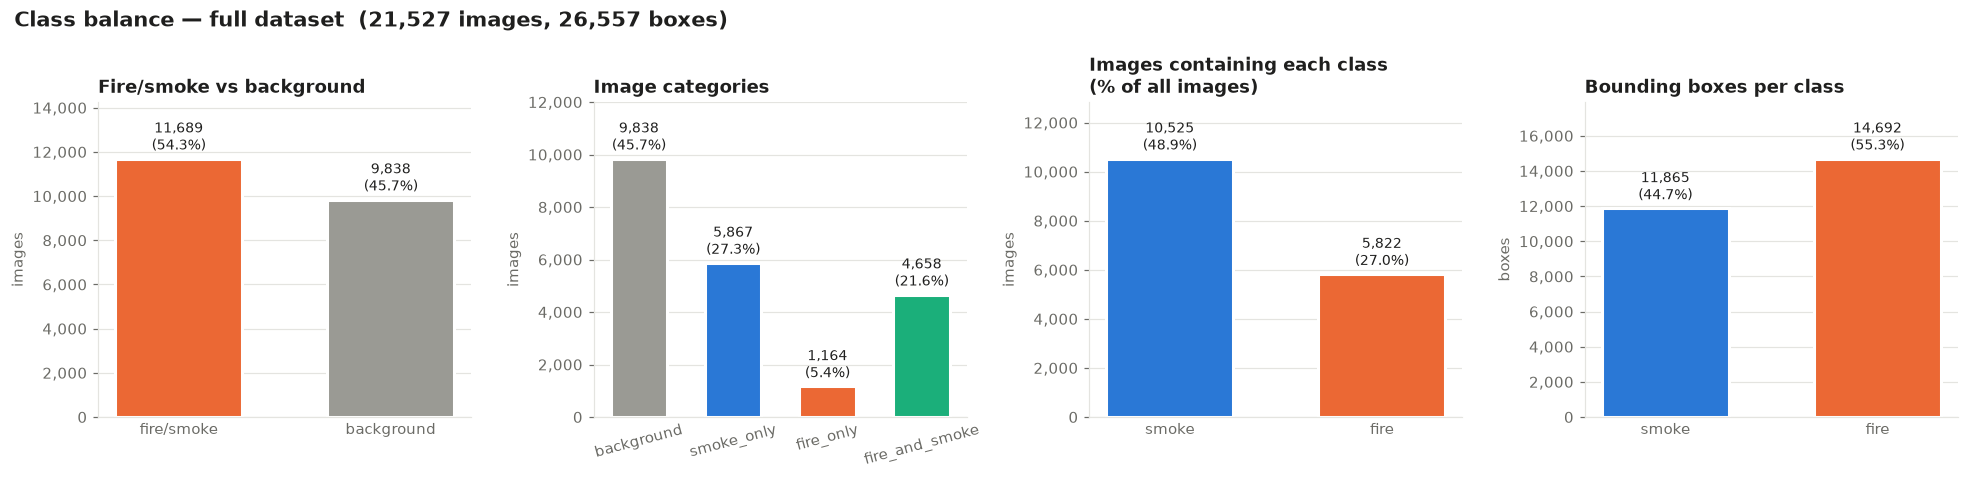

In [7]:
report(images_df, boxes_df, "full dataset")

## 6. Per split

The same analysis for each split that contains images.

=== train ===
Total images: 14,122   |   Total bounding boxes: 17,432

Fire/smoke vs background (image level)


,count,percent
has_fire_or_smoke,,
fire/smoke,7664,54.27
background,6458,45.73


Imbalance ratio (majority / minority): 1.19 : 1

Image categories


,count,percent
category,,
background,6458,45.73
smoke_only,3836,27.16
fire_only,770,5.45
fire_and_smoke,3058,21.65


Images containing each class (an image with both classes counts in both rows)


,images,percent_of_all_images
smoke,6894,48.82
fire,3828,27.11


Bounding boxes per class (instance level)


,count,percent
class,,
smoke,7794,44.71
fire,9638,55.29


Boxes per image (only images with at least one box)


,count,mean,std,min,25%,50%,75%,max
n_boxes,7664.00,2.27,1.97,1.00,1.00,1.00,3.00,22.00
n_smoke,7664.00,1.02,0.54,0.00,1.00,1.00,1.00,10.00
n_fire,7664.00,1.26,1.90,0.00,0.00,0.00,2.00,22.00


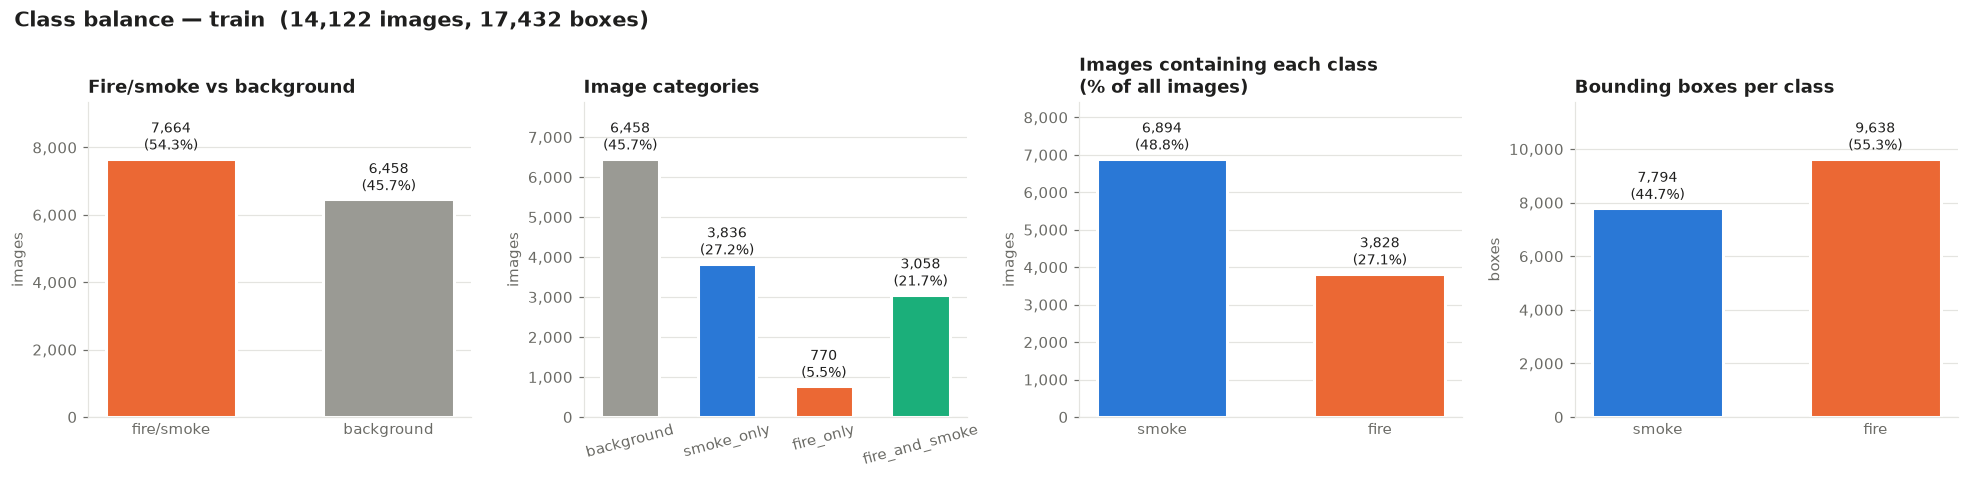

=== val ===
Total images: 3,099   |   Total bounding boxes: 3,932

Fire/smoke vs background (image level)


,count,percent
has_fire_or_smoke,,
fire/smoke,1724,55.63
background,1375,44.37


Imbalance ratio (majority / minority): 1.25 : 1

Image categories


,count,percent
category,,
background,1375,44.37
smoke_only,845,27.27
fire_only,174,5.61
fire_and_smoke,705,22.75


Images containing each class (an image with both classes counts in both rows)


,images,percent_of_all_images
smoke,1550,50.02
fire,879,28.36


Bounding boxes per class (instance level)


,count,percent
class,,
smoke,1756,44.66
fire,2176,55.34


Boxes per image (only images with at least one box)


,count,mean,std,min,25%,50%,75%,max
n_boxes,1724.00,2.28,1.91,1.00,1.00,1.00,3.00,16.00
n_smoke,1724.00,1.02,0.54,0.00,1.00,1.00,1.00,7.00
n_fire,1724.00,1.26,1.80,0.00,0.00,1.00,2.00,15.00


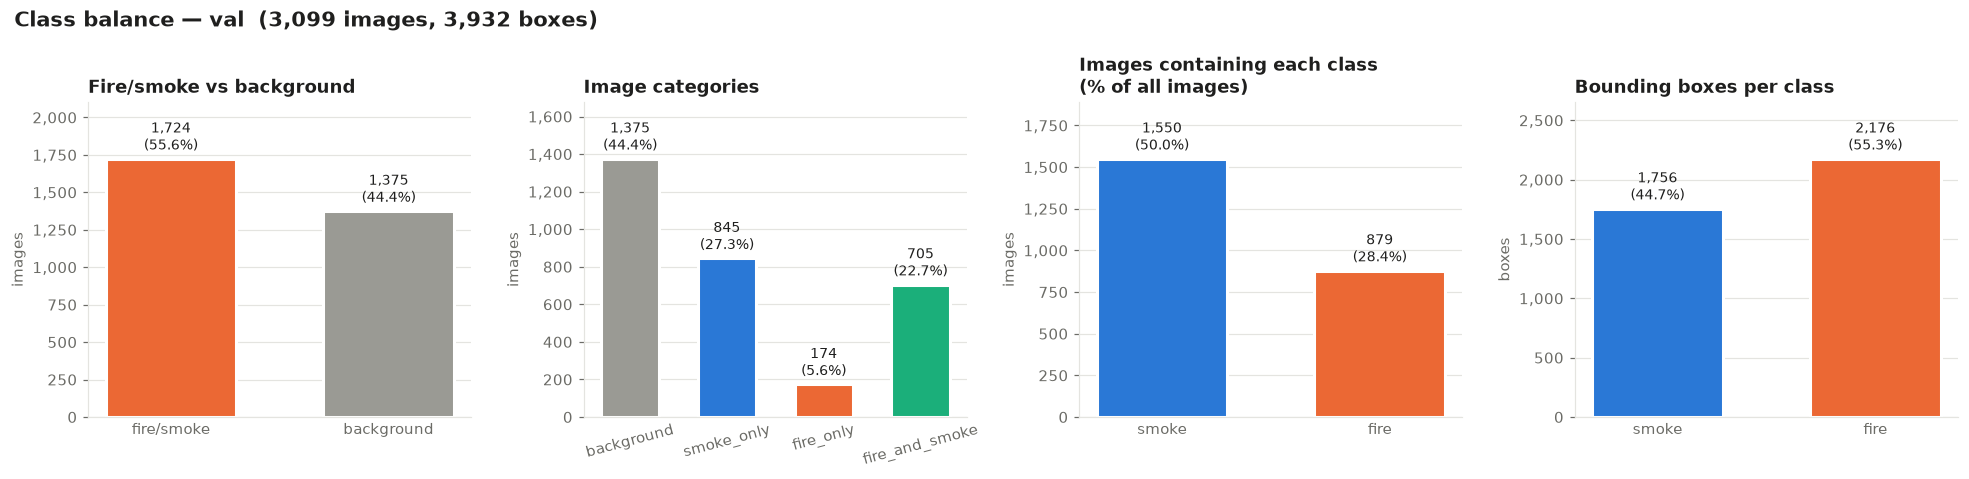

=== test ===
Total images: 4,306   |   Total bounding boxes: 5,193

Fire/smoke vs background (image level)


,count,percent
has_fire_or_smoke,,
fire/smoke,2301,53.44
background,2005,46.56


Imbalance ratio (majority / minority): 1.15 : 1

Image categories


,count,percent
category,,
background,2005,46.56
smoke_only,1186,27.54
fire_only,220,5.11
fire_and_smoke,895,20.78


Images containing each class (an image with both classes counts in both rows)


,images,percent_of_all_images
smoke,2081,48.33
fire,1115,25.89


Bounding boxes per class (instance level)


,count,percent
class,,
smoke,2315,44.58
fire,2878,55.42


Boxes per image (only images with at least one box)


,count,mean,std,min,25%,50%,75%,max
n_boxes,2301.00,2.26,1.97,1.00,1.00,1.00,3.00,23.00
n_smoke,2301.00,1.01,0.53,0.00,1.00,1.00,1.00,10.00
n_fire,2301.00,1.25,1.91,0.00,0.00,0.00,2.00,20.00


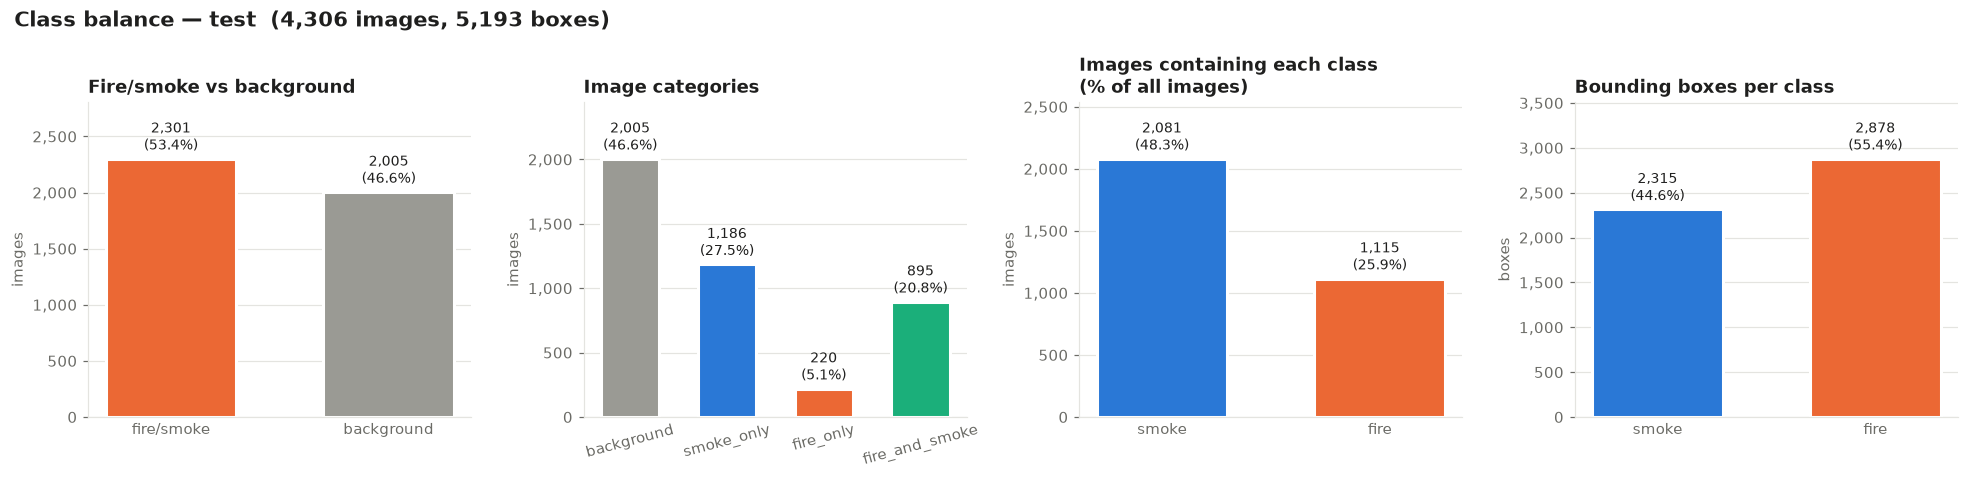

In [8]:
non_empty_splits = [s for s in SPLITS if (images_df["split"] == s).any()]

for split in SPLITS:
    if split not in non_empty_splits:
        print(f"=== {split} ===\nNo images found in {DATA_ROOT / split / 'images'} — skipped.\n")
        continue
    report(images_df[images_df["split"] == split], boxes_df[boxes_df["split"] == split], split)

### 6.1 Comparison between splits

To be a fair test, every split should have roughly the **same class proportions**.
The charts below show percentages, not counts, so splits of different sizes can be compared.

Fire/smoke vs background (images)


count               percent           
has_fire_or_smoke fire/smoke background fire/smoke background
split                                                        
train                   7664       6458      54.27      45.73
val                     1724       1375      55.63      44.37
test                    2301       2005      53.44      46.56

Image categories


count                                        percent             \
category background smoke_only fire_only fire_and_smoke background smoke_only   
split                                                                           
train          6458       3836       770           3058      45.73      27.16   
val            1375        845       174            705      44.37      27.27   
test           2005       1186       220            895      46.56      27.54   

                                   
category fire_only fire_and_smoke  
split                              
train         5.45          21.65  
val           5.61          22.75  
test          5.11          20.78

Bounding boxes per class


count       percent      
class smoke  fire   smoke  fire
split                          
train  7794  9638   44.71 55.29
val    1756  2176   44.66 55.34
test   2315  2878   44.58 55.42

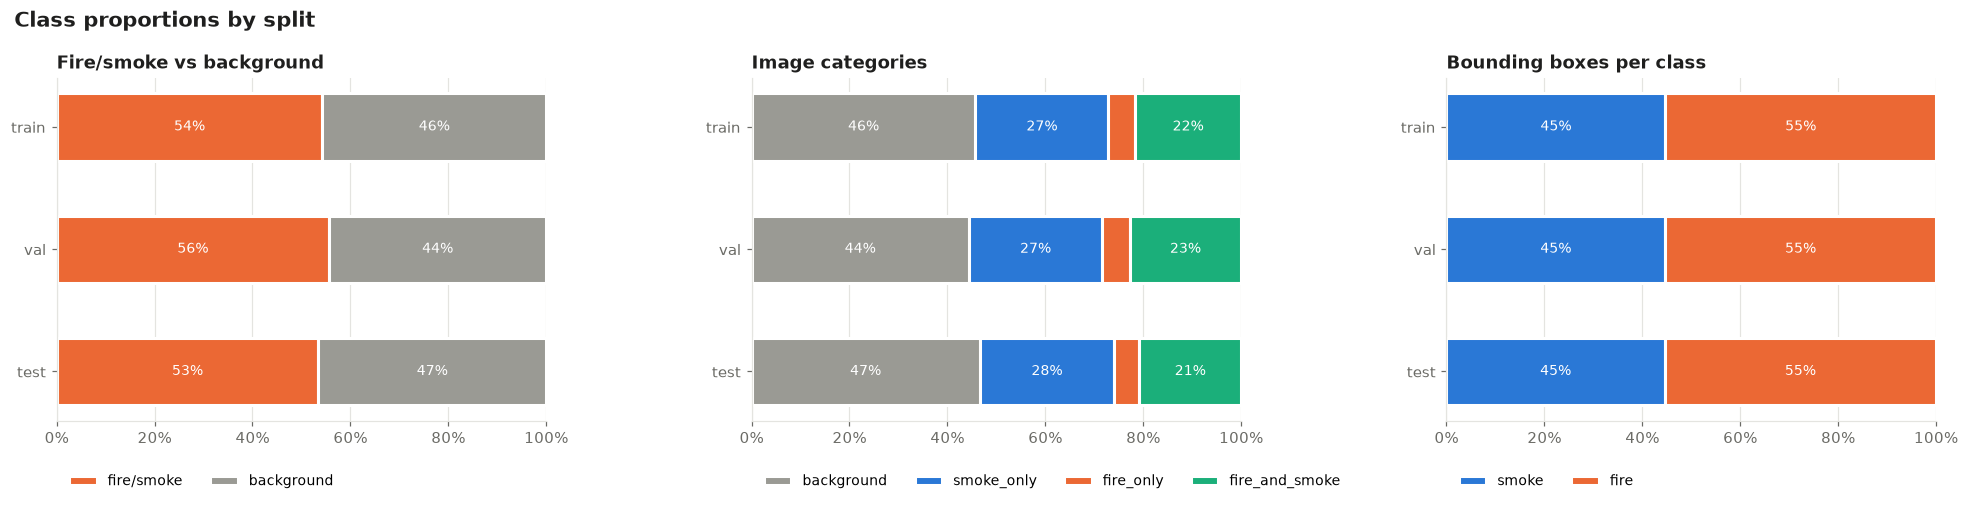

In [9]:
def proportions_by_split(values, order):
    tab = pd.crosstab(values.iloc[:, 0], values.iloc[:, 1]).reindex(index=non_empty_splits, columns=order, fill_value=0)
    return tab, tab.div(tab.sum(axis=1), axis=0) * 100


binary = images_df[["split", "has_fire_or_smoke"]].assign(
    has_fire_or_smoke=lambda d: d["has_fire_or_smoke"].map({True: "fire/smoke", False: "background"}))
bin_counts, bin_pct = proportions_by_split(binary, ["fire/smoke", "background"])
cat_counts, cat_pct = proportions_by_split(images_df[["split", "category"]], CATEGORIES)
inst_counts, inst_pct = proportions_by_split(boxes_df[["split", "class"]], ["smoke", "fire"])

for name, counts, pct in [("Fire/smoke vs background (images)", bin_counts, bin_pct),
                          ("Image categories", cat_counts, cat_pct),
                          ("Bounding boxes per class", inst_counts, inst_pct)]:
    print(name)
    display(pd.concat({"count": counts, "percent": pct}, axis=1))


def stacked_pct(ax, pct, title):
    left = np.zeros(len(pct))
    for col in pct.columns:
        vals = pct[col].values
        ax.barh(pct.index.astype(str), vals, left=left, height=0.55, color=COLORS[col],
                edgecolor="white", linewidth=2, label=col)
        for y, (l, v) in enumerate(zip(left, vals)):
            if v >= 6:
                ax.text(l + v / 2, y, f"{v:.0f}%", ha="center", va="center", fontsize=9, color="white")
        left += vals
    ax.set_xlim(0, 100)
    ax.xaxis.set_major_formatter(mticker.PercentFormatter())
    ax.grid(axis="x"); ax.grid(axis="y", visible=False)
    ax.invert_yaxis()
    ax.set_title(title, loc="left")
    ax.legend(ncol=len(pct.columns), loc="upper left", bbox_to_anchor=(0, -0.12), fontsize=9)


if non_empty_splits:
    fig, axes = plt.subplots(1, 3, figsize=(18, 0.7 * len(non_empty_splits) + 2.6))
    stacked_pct(axes[0], bin_pct, "Fire/smoke vs background")
    stacked_pct(axes[1], cat_pct, "Image categories")
    stacked_pct(axes[2], inst_pct, "Bounding boxes per class")
    fig.suptitle("Class proportions by split", x=0.01, ha="left", fontsize=14, fontweight="bold", color=TEXT)
    fig.tight_layout()
    plt.show()